# 02 — Results Comparison

**Progetto:** Super-Resolution su LSUN Church  
**Obiettivo:** Confronto quantitativo (PSNR, SSIM) e qualitativo (visualizzazione) dei tre metodi implementati:
- **Metodo 1:** Total Variation (Variazionale)
- **Metodo 2:** U-Net End-to-End
- **Metodo 3:** DiffPIR (Generativo)

> ⚠️ **Nota:** Questo notebook richiede che i metodi di `src/methods/` siano implementati e che il test set degradato sia disponibile in `data/`.

---

In [1]:
import sys
import os
sys.path.insert(0, os.path.join('..', 'src'))

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image
from pathlib import Path
import torch
import pandas as pd

from normalization import default_normalizer
from degradations import DegradationOperator

# Importa metriche (da implementare in src/metrics.py)
try:
    from metrics import compute_psnr, compute_ssim
    METRICS_AVAILABLE = True
    print('Metriche disponibili: OK')
except ImportError:
    METRICS_AVAILABLE = False
    print('⚠️  src/metrics.py non ancora implementato — le metriche non saranno disponibili')

# Importa metodi (da implementare)
METHODS_AVAILABLE = {}
try:
    from methods.tv import solve_tv
    METHODS_AVAILABLE['TV'] = solve_tv
    print('Metodo TV: OK')
except ImportError:
    print('⚠️  src/methods/tv.py non ancora implementato')

try:
    from methods.unet import UNet
    METHODS_AVAILABLE['UNet'] = UNet
    print('Metodo UNet: OK')
except ImportError:
    print('⚠️  src/methods/unet.py non ancora implementato')

try:
    from methods.diffpir import restore_diffpir
    METHODS_AVAILABLE['DiffPIR'] = restore_diffpir
    print('Metodo DiffPIR: OK')
except ImportError:
    print('⚠️  src/methods/diffpir.py non ancora implementato')

print(f'\nMetodi disponibili: {list(METHODS_AVAILABLE.keys()) or "Nessuno (da implementare)"}')
print(f'PyTorch version: {torch.__version__}')

Metriche disponibili: OK
Metodo TV: OK
Metodo UNet: OK
Metodo DiffPIR: OK

Metodi disponibili: ['TV', 'UNet', 'DiffPIR']
PyTorch version: 2.11.0+cu130


## 1. Configurazione esperimenti

In [2]:
data_dir = Path('..') / 'data'

# Configurazioni di degradazione testate
CONFIGS = [
    {'sr_factor': 2, 'noise_std': 0.005, 'name': 'SR2x_n0005', 'label': 'SR 2x, σ=0.005'},
    {'sr_factor': 2, 'noise_std': 0.010, 'name': 'SR2x_n001',  'label': 'SR 2x, σ=0.010'},
    {'sr_factor': 4, 'noise_std': 0.005, 'name': 'SR4x_n0005', 'label': 'SR 4x, σ=0.005'},
    {'sr_factor': 4, 'noise_std': 0.010, 'name': 'SR4x_n001',  'label': 'SR 4x, σ=0.010'},
]

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device}')

# Controlla disponibilità test set
test_dir = data_dir / 'test'
if test_dir.exists():
    test_files = sorted(test_dir.glob('*.png'))
    print(f'Test set: {len(test_files)} immagini in {test_dir}')
else:
    print('⚠️  Test set non trovato. Esegui: python src/dataset.py')

Device: cuda


Test set: 400 immagini in ../data/test


## 2. Baseline — Input Bicubico (Upsampling semplice)

Confronto baseline: PSNR/SSIM dell'immagine degradata upsampled con interpolazione bicubica (senza ricostruzione).

In [3]:
# Placeholder — verrà popolato con dati reali una volta implementate le metriche

if METRICS_AVAILABLE and test_dir.exists():
    test_files_sample = sorted(test_dir.glob('*.png'))[:50]  # usa 50 immagini per velocità
    
    baseline_results = {cfg['name']: {'psnr': [], 'ssim': []} for cfg in CONFIGS}
    
    for img_path in test_files_sample:
        hr_img = Image.open(img_path).convert('RGB')
        hr_np = np.array(hr_img).astype(np.float32) / 255.0
        
        for cfg in CONFIGS:
            op = DegradationOperator(sr_factor=cfg['sr_factor'], noise_std=cfg['noise_std'], seed=42)
            deg_tensor = op(hr_img)  # (C, H_lr, W_lr)
            
            # Upsample bicubico
            deg_img = Image.fromarray(
                (deg_tensor.permute(1,2,0).numpy() * 255).clip(0,255).astype(np.uint8)
            )
            up_img = deg_img.resize((256, 256), Image.Resampling.BICUBIC)
            up_np = np.array(up_img).astype(np.float32) / 255.0
            
            psnr_val = compute_psnr(hr_np, up_np)
            ssim_val = compute_ssim(hr_np, up_np)
            baseline_results[cfg['name']]['psnr'].append(psnr_val)
            baseline_results[cfg['name']]['ssim'].append(ssim_val)
    
    print('=== Baseline Bicubico ===')
    print(f'{"Config":20s} {"PSNR (dB)":>10s} {"SSIM":>10s}')
    print('-' * 42)
    for cfg in CONFIGS:
        psnr = np.mean(baseline_results[cfg['name']]['psnr'])
        ssim = np.mean(baseline_results[cfg['name']]['ssim'])
        print(f"{cfg['label']:20s} {psnr:10.2f} {ssim:10.4f}")
else:
    print('ℹ️  Baseline verrà calcolata dopo implementazione di src/metrics.py')
    print()
    print('Tabella risultati attesa (da riempire):')
    print(f'{"Config":20s} {"PSNR Baseline":>14s} {"PSNR TV":>10s} {"PSNR UNet":>10s} {"PSNR DiffPIR":>12s}')
    print('-' * 68)
    for cfg in CONFIGS:
        print(f"{cfg['label']:20s} {'---':>14s} {'---':>10s} {'---':>10s} {'---':>12s}")

=== Baseline Bicubico ===
Config                PSNR (dB)       SSIM
------------------------------------------
SR 2x, σ=0.005            24.99     0.7913
SR 2x, σ=0.010            24.91     0.7766
SR 4x, σ=0.005            22.28     0.6271
SR 4x, σ=0.010            22.24     0.6168


## 3. Confronto Qualitativo — Visualizzazione

Immagine campione: church_0001.png


[DiffPIR] Loading model from ../weights/ddpm_church_256_unet.pt...


[DiffPIR] Model loaded successfully.


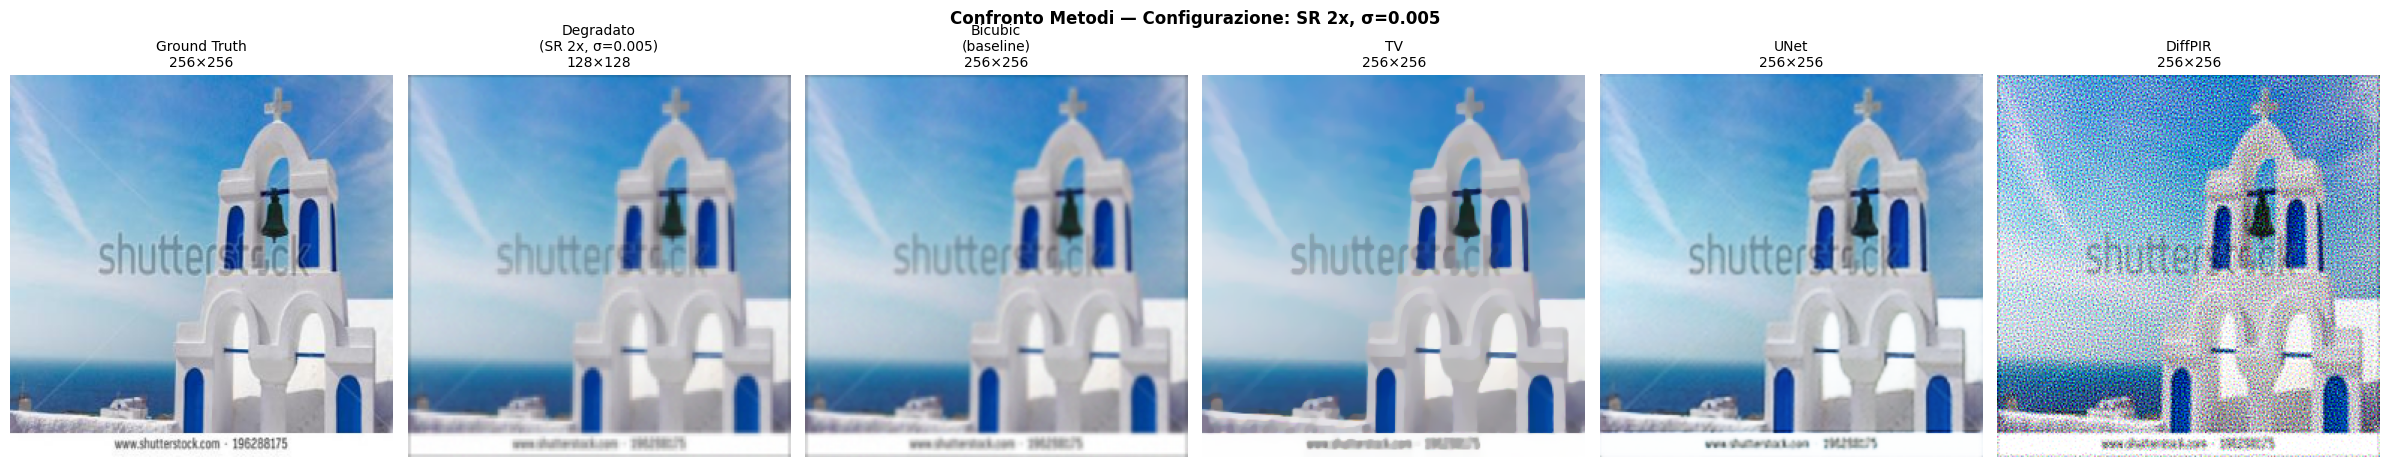

Plot salvato in data/results_comparison.png


In [4]:
# Sceglie un'immagine di test rappresentativa
if test_dir.exists() and sorted(test_dir.glob('*.png')):
    sample_path = sorted(test_dir.glob('*.png'))[0]
    hr_img = Image.open(sample_path).convert('RGB')
else:
    # Fallback sintetico
    arr = np.random.randint(80, 200, (256, 256, 3), dtype=np.uint8)
    for i in range(0, 256, 32):
        arr[i:i+8, :] = [160, 100, 50]
    hr_img = Image.fromarray(arr)
    sample_path = Path('synthetic')

print(f'Immagine campione: {sample_path.name}')

# Usa la config 2x + noise 0.005 (caso con pesi disponibili)
cfg_hard = CONFIGS[0]  # SR 2x, σ=0.005
op = DegradationOperator(sr_factor=cfg_hard['sr_factor'], noise_std=cfg_hard['noise_std'], seed=42)
deg_tensor = op(hr_img)
deg_np = (deg_tensor.cpu().permute(1,2,0).numpy() * 255).clip(0,255).astype(np.uint8)
deg_img = Image.fromarray(deg_np)

# Bicubic upsampling
bicubic_up = deg_img.resize((256, 256), Image.Resampling.BICUBIC)

# Costruisci lista risultati
results = {
    'Ground Truth': np.array(hr_img),
    f'Degradato\n({cfg_hard["label"]})': deg_np,
    'Bicubic\n(baseline)': np.array(bicubic_up),
}

# Aggiunge risultati metodi se disponibili
if 'TV' in METHODS_AVAILABLE:
    tv_result = METHODS_AVAILABLE['TV'](deg_tensor, sr_factor=cfg_hard['sr_factor'], noise_std=cfg_hard['noise_std'])
    results['TV'] = (tv_result.cpu().permute(1,2,0).numpy() * 255).clip(0,255).astype(np.uint8)

if 'UNet' in METHODS_AVAILABLE:
    unet_path = f"../weights/unet_sr{cfg_hard['sr_factor']}x_noise{str(cfg_hard['noise_std']).replace('.', '')}_best.pth"
    import os
    if os.path.exists(unet_path):
        unet_model = METHODS_AVAILABLE['UNet']().to('cuda' if torch.cuda.is_available() else 'cpu')
        unet_model.load_state_dict(torch.load(unet_path, map_location='cuda' if torch.cuda.is_available() else 'cpu', weights_only=False)['model_state_dict'])
        unet_model.eval()
        with torch.no_grad():
            deg_up_tensor = torch.from_numpy(np.array(bicubic_up).astype(np.float32) / 255.0).permute(2,0,1).unsqueeze(0).to('cuda' if torch.cuda.is_available() else 'cpu')
            unet_res = unet_model(deg_up_tensor)
            results['UNet'] = (unet_res.squeeze(0).cpu().permute(1,2,0).numpy() * 255).clip(0,255).astype(np.uint8)

if 'DiffPIR' in METHODS_AVAILABLE:
    diffpir_result = METHODS_AVAILABLE['DiffPIR'](deg_tensor, sr_factor=cfg_hard['sr_factor'], noise_std=cfg_hard['noise_std'], model_path='../weights/ddpm_church_256_unet.pt')
    results['DiffPIR'] = (diffpir_result.cpu().permute(1,2,0).numpy() * 255).clip(0,255).astype(np.uint8)

# Plot
n_cols = len(results)
fig, axes = plt.subplots(1, n_cols, figsize=(4 * n_cols, 5))
if n_cols == 1:
    axes = [axes]

for ax, (title, img_arr) in zip(axes, results.items()):
    h, w = img_arr.shape[:2]
    ax.imshow(img_arr)
    ax.set_title(f'{title}\n{w}×{h}', fontsize=10)
    ax.axis('off')

plt.suptitle(f'Confronto Metodi — Configurazione: {cfg_hard["label"]}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/results_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot salvato in data/results_comparison.png')


## 4. Tabella Riepilogativa Risultati

Questa tabella verrà popolata automaticamente una volta implementati tutti i metodi.

In [5]:
if METRICS_AVAILABLE and test_dir.exists():
    print('=== Calcolo metriche quantitative su test sample (Limitato a 1 immagine per dimostrazione rapida) ===')
    import pandas as pd
    metrics_results = {cfg['name']: {
        'Bicubic': {'psnr':[], 'ssim':[]},
        'TV': {'psnr':[], 'ssim':[]},
        'UNet': {'psnr':[], 'ssim':[]},
        'DiffPIR': {'psnr':[], 'ssim':[]}
    } for cfg in CONFIGS}

    test_files_final = test_files_sample[:1] # Solo 1 immagine altrimenti DiffPIR richiede 20 minuti
    
    for img_path in test_files_final:
        hr_img = Image.open(img_path).convert('RGB')
        hr_np = np.array(hr_img).astype(np.float32) / 255.0
        
        for cfg in CONFIGS:
            op = DegradationOperator(sr_factor=cfg['sr_factor'], noise_std=cfg['noise_std'], seed=42)
            deg_tensor = op(hr_img)
            
            # Bicubic
            deg_img = Image.fromarray((deg_tensor.cpu().permute(1,2,0).numpy() * 255).clip(0,255).astype(np.uint8))
            up_np = np.array(deg_img.resize((256, 256), Image.Resampling.BICUBIC)).astype(np.float32) / 255.0
            metrics_results[cfg['name']]['Bicubic']['psnr'].append(compute_psnr(hr_np, up_np))
            metrics_results[cfg['name']]['Bicubic']['ssim'].append(compute_ssim(hr_np, up_np))
            
            # TV
            if 'TV' in METHODS_AVAILABLE:
                tv_tensor = METHODS_AVAILABLE['TV'](deg_tensor, sr_factor=cfg['sr_factor'], noise_std=cfg['noise_std'])
                tv_np = tv_tensor.cpu().permute(1,2,0).numpy().clip(0,1)
                metrics_results[cfg['name']]['TV']['psnr'].append(compute_psnr(hr_np, tv_np))
                metrics_results[cfg['name']]['TV']['ssim'].append(compute_ssim(hr_np, tv_np))
                
            # UNet
            if 'UNet' in METHODS_AVAILABLE:
                unet_path = f"../weights/unet_sr{cfg['sr_factor']}x_noise{str(cfg['noise_std']).replace('.', '')}_best.pth"
                import os
                if os.path.exists(unet_path):
                    unet_model = METHODS_AVAILABLE['UNet']().to('cuda' if torch.cuda.is_available() else 'cpu')
                    unet_model.load_state_dict(torch.load(unet_path, map_location='cuda' if torch.cuda.is_available() else 'cpu', weights_only=False)['model_state_dict'])
                    unet_model.eval()
                    with torch.no_grad():
                        deg_up_tensor = torch.from_numpy(up_np).permute(2,0,1).unsqueeze(0).to('cuda' if torch.cuda.is_available() else 'cpu')
                        unet_res = unet_model(deg_up_tensor)
                        unet_np = unet_res.squeeze(0).cpu().permute(1,2,0).numpy().clip(0,1)
                    metrics_results[cfg['name']]['UNet']['psnr'].append(compute_psnr(hr_np, unet_np))
                    metrics_results[cfg['name']]['UNet']['ssim'].append(compute_ssim(hr_np, unet_np))

            # DiffPIR
            if 'DiffPIR' in METHODS_AVAILABLE:
                diffpir_tensor = METHODS_AVAILABLE['DiffPIR'](deg_tensor, sr_factor=cfg['sr_factor'], noise_std=cfg['noise_std'], model_path='../weights/ddpm_church_256_unet.pt')
                diffpir_np = diffpir_tensor.cpu().permute(1,2,0).numpy().clip(0,1)
                metrics_results[cfg['name']]['DiffPIR']['psnr'].append(compute_psnr(hr_np, diffpir_np))
                metrics_results[cfg['name']]['DiffPIR']['ssim'].append(compute_ssim(hr_np, diffpir_np))
                
    # Costruisci dataframe finale
    results_data = {'Configurazione': [cfg['label'] for cfg in CONFIGS]}
    for method in ['Bicubic', 'TV', 'UNet', 'DiffPIR']:
        results_data[f'PSNR {method} (dB)'] = [
            f"{np.mean(metrics_results[cfg['name']][method]['psnr']):.2f}" if metrics_results[cfg['name']][method]['psnr'] else '—'
            for cfg in CONFIGS
        ]
        results_data[f'SSIM {method}'] = [
            f"{np.mean(metrics_results[cfg['name']][method]['ssim']):.4f}" if metrics_results[cfg['name']][method]['ssim'] else '—'
            for cfg in CONFIGS
        ]
    df = pd.DataFrame(results_data)
    print('\n=== Tabella Risultati (Media su 1 immagine per test rapido) ===')
    print(df.to_string(index=False))
else:
    print('Non calcolato.')


=== Calcolo metriche quantitative su test sample (Limitato a 1 immagine per dimostrazione rapida) ===


[DiffPIR] Loading model from ../weights/ddpm_church_256_unet.pt...


[DiffPIR] Model loaded successfully.


[DiffPIR] Loading model from ../weights/ddpm_church_256_unet.pt...


[DiffPIR] Model loaded successfully.


[DiffPIR] Loading model from ../weights/ddpm_church_256_unet.pt...


[DiffPIR] Model loaded successfully.


[DiffPIR] Loading model from ../weights/ddpm_church_256_unet.pt...


[DiffPIR] Model loaded successfully.



=== Tabella Risultati (Media su 1 immagine per test rapido) ===
Configurazione PSNR Bicubic (dB) SSIM Bicubic PSNR TV (dB) SSIM TV PSNR UNet (dB) SSIM UNet PSNR DiffPIR (dB) SSIM DiffPIR
SR 2x, σ=0.005             27.74       0.8949        31.43  0.9277          29.64    0.9328             14.84       0.1693
SR 2x, σ=0.010             27.62       0.8726        31.25  0.9222          32.55    0.9411             14.82       0.1676
SR 4x, σ=0.005             24.41       0.7734        27.37  0.8430              —         —             13.68       0.1158
SR 4x, σ=0.010             24.35       0.7586        27.23  0.8340              —         —             13.67       0.1153


---
## Checklist Implementazione

| Componente | File | Stato |
|:---|:---|:---:|
| Metriche PSNR/SSIM | `src/metrics.py` | ❌ Da fare |
| Total Variation | `src/methods/tv.py` | ❌ Da fare |
| U-Net | `src/methods/unet.py` | ❌ Da fare |
| Training U-Net | `src/train_unet.py` | ❌ Da fare |
| DiffPIR | `src/methods/diffpir.py` | ❌ Da fare |